# London Household Electricity Demand: Big Data Forecasting with PySpark

**Data:** [Smart meters in London](https://www.kaggle.com/datasets/jeanmidev/smart-meters-in-london): half-hourly electricity readings from about 5,500 London households (November 2011 to February 2014), plus household tariff information, hourly weather, and UK bank holidays.

**Questions**

1. **Can we forecast household electricity demand a day ahead?** This is the problem energy suppliers actually solve to plan how much electricity to buy.
2. **What drives demand?** Time of day, season, temperature, holidays.
3. **Did time-of-use pricing change behaviour?** In this trial, about 1 in 5 households was placed on a dynamic time-of-use (ToU) tariff during 2013, with prices that varied by time of day. Did those households use less electricity in the evening peak?

**Approach:** PySpark processes all 167.8 million raw readings on a single machine and reduces them to compact tables. The forecasting models are then trained on those tables with scikit-learn.

## 1. Setup

In [1]:
# PySpark needs Java. On Kaggle, turn on Internet in the notebook settings so missing packages can be installed.
import importlib.util, shutil, subprocess, sys
if shutil.which("java") is None:
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jre-headless", shell=True, check=True)
if importlib.util.find_spec("pyspark") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.strip().splitlines()[-1])

OpenJDK 64-Bit Server VM (build 21.0.12+8-1-24.04-Ubuntu, mixed mode, sharing)


In [2]:
import glob, os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from pyspark.sql import SparkSession, functions as F, Window

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
COLORS = {"Std": "#12355B", "ToU": "#E0A030"}

spark = (SparkSession.builder
         .appName("London smart meters")
         .master("local[*]")
         .config("spark.driver.memory", "12g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/15 08:07:16 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.4


In [3]:
# Locate the dataset (works on Kaggle, or locally by setting DATA_ROOT)
DATA_ROOT = os.environ.get("DATA_ROOT", "/kaggle/input")

def find(pattern):
    hits = sorted(glob.glob(os.path.join(DATA_ROOT, "**", pattern), recursive=True))
    assert hits, f"Could not find {pattern} under {DATA_ROOT}"
    return hits

HALFHOURLY_FILES = [f for f in find("block_*.csv") if "halfhourly" in f]
HOUSEHOLDS_FILE = find("informations_households*")[0]
WEATHER_FILE = find("weather_hourly_darksky*")[0]
HOLIDAYS_FILE = find("uk_bank_holidays*")[0]
print(f"{len(HALFHOURLY_FILES)} half-hourly block files")

112 half-hourly block files


## 2. Load and Clean the Raw Readings with Spark

The raw files have a few quirks that a careless load would get wrong:

- energy values are stored as **text padded with spaces**, and missing values are the literal word `Null`
- timestamps carry fractional seconds (`2011-12-08 12:30:00.0000000`)
- a household could report the same half hour twice, so duplicates must be checked

So every column is read as text first, then cleaned explicitly. The audit below finds 5,560 missing values and no duplicates or negative readings.

In [4]:
raw = (spark.read.option("header", True).schema("LCLid STRING, tstp STRING, energy STRING")
       .csv(HALFHOURLY_FILES))

readings = (raw
    .withColumn("ts", F.to_timestamp(F.substring(F.trim("tstp"), 1, 19), "yyyy-MM-dd HH:mm:ss"))
    .withColumn("energy", F.when(F.trim("energy") == "Null", None).otherwise(F.trim("energy")).cast("double"))
    .select("LCLid", "ts", "energy"))

valid_row = F.col("ts").isNotNull() & F.col("energy").isNotNull() & (F.col("energy") >= 0)
audit = readings.agg(
    F.count("*").alias("raw_rows"),
    F.countDistinct("LCLid").alias("raw_households"),
    F.sum(F.col("energy").isNull().cast("int")).alias("missing_energy"),
    F.sum(F.col("ts").isNull().cast("int")).alias("unreadable_timestamps"),
    F.sum((F.col("energy") < 0).cast("int")).alias("negative_energy"),
    F.sum(valid_row.cast("int")).alias("valid_rows"),
).first().asDict()

# Keep valid readings, remove duplicated (household, timestamp) pairs, and cache the result for reuse
clean = readings.filter(valid_row).dropDuplicates(["LCLid", "ts"]).persist()
audit["rows_after_cleaning"] = clean.count()
audit["duplicates_removed"] = audit["valid_rows"] - audit["rows_after_cleaning"]
pd.Series(audit).map("{:,}".format)

raw_rows                 167,817,021
raw_households                 5,566
missing_energy                 5,560
unreadable_timestamps              0
negative_energy                    0
valid_rows               167,811,461
rows_after_cleaning      167,811,461
duplicates_removed                 0
dtype: object

In [5]:
summary = clean.agg(F.countDistinct("LCLid").alias("households"),
                    F.min("ts").alias("first_reading"), F.max("ts").alias("last_reading"),
                    F.mean("energy").alias("mean_kwh_per_half_hour")).first().asDict()
summary

{'households': 5561,
 'first_reading': datetime.datetime(2011, 11, 23, 9, 0),
 'last_reading': datetime.datetime(2014, 2, 28, 0, 0),
 'mean_kwh_per_half_hour': 0.21178424342771923}

## 3. Data Audit: How Many Households Are Reporting?

Smart meters were installed gradually, so the number of households reporting changes over time. If we simply **summed** consumption, demand would appear to grow just because more meters came online. The target must therefore be the **average consumption per reporting household**.

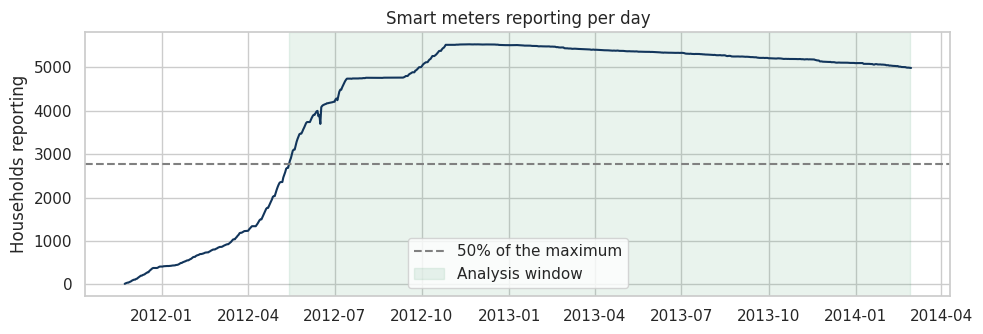

Analysis window: 2012-05-14 to 2014-02-27


In [6]:
daily_households = (clean.groupBy(F.to_date("ts").alias("date"))
                    .agg(F.countDistinct("LCLid").alias("households"),
                         F.countDistinct("ts").alias("half_hours"))
                    .orderBy("date").toPandas())
daily_households["date"] = pd.to_datetime(daily_households["date"])

threshold = 0.5 * daily_households["households"].max()
# Keep days with enough households AND all 48 half hours (the last file ends at midnight on 28 Feb 2014)
stable = daily_households[(daily_households["households"] >= threshold) & (daily_households["half_hours"] == 48)]
START, END = stable["date"].min(), stable["date"].max()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily_households["date"], daily_households["households"], color="#12355B")
ax.axhline(threshold, ls="--", c="grey", label="50% of the maximum")
ax.axvspan(START, END, color="#4C9F70", alpha=0.12, label="Analysis window")
ax.set_ylabel("Households reporting")
ax.set_title("Smart meters reporting per day")
ax.legend(loc="lower center")
plt.tight_layout()
plt.show()
print(f"Analysis window: {START.date()} to {END.date()}")

The analysis keeps the period where at least half of the maximum number of households are reporting, and only complete days with all 48 half hours. Before it, the average is based on too few meters to be stable; at the very end, meters drop out as the trial closes.

## 4. Aggregate to a Demand Series

Spark reduces the readings to one row per half hour: average consumption per household and the number of households reporting.

In [7]:
demand = (clean.filter((F.col("ts") >= F.lit(str(START.date()))) & (F.col("ts") < F.lit(str((END + pd.Timedelta(days=1)).date()))))
          .groupBy("ts")
          .agg(F.mean("energy").alias("kwh_per_household"), F.countDistinct("LCLid").alias("households"))
          .orderBy("ts").toPandas())
demand["ts"] = pd.to_datetime(demand["ts"])
demand = demand.set_index("ts").asfreq("30min")
print(f"{len(demand):,} half-hour slots, {demand['kwh_per_household'].isna().sum()} with no readings")
demand["kwh_per_household"] = demand["kwh_per_household"].interpolate(limit=4)
demand.head()

31,440 half-hour slots, 0 with no readings


,kwh_per_household,households
ts,,
2012-05-14 00:00:00,0.131878,2684
2012-05-14 00:30:00,0.153382,2685
2012-05-14 01:00:00,0.140862,2685
2012-05-14 01:30:00,0.128754,2685
2012-05-14 02:00:00,0.115842,2685


In [8]:
weather = pd.read_csv(WEATHER_FILE, usecols=["time", "temperature"], parse_dates=["time"])
weather = weather.drop_duplicates("time").set_index("time").sort_index()["temperature"]
weather = weather.resample("30min").interpolate(limit=6)

### Bank holiday dates need fixing

The holidays file looks like `YYYY-MM-DD`, but many rows are actually `YYYY-DD-MM`. For example, `2012-09-04` is labelled *Easter Monday*, which was 9 April 2012, not 4 September, and `2012-05-06` is the *Diamond Jubilee*, which was 5 June. Reading the column naively puts these holidays on the wrong days.

The rows follow a consistent pattern: when the last number is above 12 it can only be a day (`YYYY-MM-DD`); otherwise the date is stored as `YYYY-DD-MM`. The table below compares the naive reading with the corrected one, and the holiday names confirm the correction (Easter in spring, Early May bank holiday in May, and so on).

In [9]:
holidays = pd.read_csv(HOLIDAYS_FILE, encoding="latin-1")
holidays.columns = ["raw_date", "holiday_name"]
holidays["holiday_name"] = holidays["holiday_name"].str.replace("?", "'", regex=False)

def parse_holiday(text):
    year, a, b = (int(x) for x in str(text).strip().split("-"))
    month, day = (a, b) if b > 12 else (b, a)
    return pd.Timestamp(year=year, month=month, day=day)

holidays["naive_date"] = pd.to_datetime(holidays["raw_date"], errors="coerce")
holidays["corrected_date"] = holidays["raw_date"].map(parse_holiday)
holidays["changed"] = holidays["naive_date"] != holidays["corrected_date"]
holiday_dates = set(holidays["corrected_date"])
print(f"{holidays['changed'].sum()} of {len(holidays)} dates were stored day-first")
holidays.sort_values("corrected_date")[["raw_date", "naive_date", "corrected_date", "holiday_name", "changed"]]

8 of 25 dates were stored day-first


,raw_date,naive_date,corrected_date,holiday_name,changed
8,2012-02-01,2012-02-01,2012-01-02,New Year's Day (substitute day),True
7,2012-06-04,2012-06-04,2012-04-06,Good Friday,True
6,2012-09-04,2012-09-04,2012-04-09,Easter Monday,True
5,2012-07-05,2012-07-05,2012-05-07,Early May bank holiday,True
4,2012-04-06,2012-04-06,2012-06-04,Spring bank holiday (substitute day),True
3,2012-05-06,2012-05-06,2012-06-05,Queen's Diamond Jubilee (extra bank holiday),True
2,2012-08-27,2012-08-27,2012-08-27,Summer bank holiday,False
1,2012-12-25,2012-12-25,2012-12-25,Christmas Day,False
0,2012-12-26,2012-12-26,2012-12-26,Boxing Day,False
16,2013-01-01,2013-01-01,2013-01-01,New Year's Day,False


In [10]:
demand["temperature"] = weather.reindex(demand.index)
local_dates = demand.index.tz_localize("UTC").tz_convert("Europe/London").tz_localize(None).normalize()
demand["holiday"] = local_dates.isin(holiday_dates).astype(int)
print("Missing temperature values:", demand["temperature"].isna().sum())
demand["temperature"] = demand["temperature"].interpolate(limit_direction="both")

Missing temperature values: 0


### Data funnel

How many households and readings survive each step, from the raw files to the analysis window. All 112 half-hourly block files of the original dataset are used. Cleaning removes missing values and duplicates: households whose readings are all `Null` drop out at this step because they have no usable data. The analysis window keeps complete days with enough meters reporting. In this dataset 5 of the 5,566 registered households have only `Null` values, so 5,561 households remain, with 160.4 million readings inside the analysis window.

In [11]:
registered = pd.read_csv(HOUSEHOLDS_FILE)["LCLid"].nunique()
in_window = clean.filter((F.col("ts") >= F.lit(str(START.date()))) & (F.col("ts") < F.lit(str((END + pd.Timedelta(days=1)).date()))))
window_stats = in_window.agg(F.count("*").alias("readings"), F.countDistinct("LCLid").alias("households")).first()

funnel = pd.DataFrame([
    ("Registered in the households file", registered, None),
    (f"Raw readings ({len(HALFHOURLY_FILES)} files)", audit["raw_households"], audit["raw_rows"]),
    ("After cleaning", summary["households"], audit["rows_after_cleaning"]),
    (f"Analysis window ({START.date()} to {END.date()})", window_stats["households"], window_stats["readings"]),
], columns=["Stage", "Households", "Readings"]).set_index("Stage")
funnel.map(lambda v: "" if pd.isna(v) else f"{int(v):,}")

,Households,Readings
Stage,,
Registered in the households file,"5,566",
Raw readings (112 files),"5,566","167,817,021"
After cleaning,"5,561","167,811,461"
Analysis window (2012-05-14 to 2014-02-27),"5,561","160,388,865"


### Time zone check

Clock changes are a classic source of silent errors. London moves its clocks forward one hour in late March (BST) and back in late October. If the timestamps were in local clock time, the spring change day would have only 46 half hours and the autumn one 50. Checking both days in the meter data and the weather file shows which time standard each source uses.

In [12]:
weather_hours = pd.read_csv(WEATHER_FILE, usecols=["time"], parse_dates=["time"])["time"].dt.normalize()
dst_days = ["2013-03-31", "2013-10-27"]
pd.DataFrame({"Half hours of meter readings": [demand.loc[day, "kwh_per_household"].notna().sum() for day in dst_days],
              "Hours of weather data": [(weather_hours == day).sum() for day in dst_days]},
             index=["Clocks go forward (31 Mar 2013)", "Clocks go back (27 Oct 2013)"])

,Half hours of meter readings,Hours of weather data
Clocks go forward (31 Mar 2013),48,24
Clocks go back (27 Oct 2013),48,24


Both sources have a normal day (48 half hours, 24 hours) on the clock-change days, so **both are recorded in GMT all year** and are correctly aligned with each other. People, however, live by the clock on the wall: in summer, 16:00 GMT is 17:00 in London. From here on, every behavioural feature (time of day, day of week, month, holidays, and the evening peak window) is computed in **London local time**.

**How the clock-change days are handled:** the data itself stays indexed in GMT, so every day keeps exactly 48 half hours and no reading is lost or counted twice. Local time is only used to *label* each reading with its clock hour, weekday, month, and holiday. On the two clock-change days a local calendar day contains 46 or 50 half hours, but no calculation depends on a local day having exactly 48: daily totals and the analysis window use GMT days, and the evening peak (16:00 to 20:00) is unaffected because clocks change at 01:00 or 02:00 at night.

In [13]:
def to_local(index):
    # Timestamps are GMT all year; convert to London clock time (GMT in winter, BST in summer)
    return pd.DatetimeIndex(index).tz_localize("UTC").tz_convert("Europe/London")

## 5. Exploratory Analysis

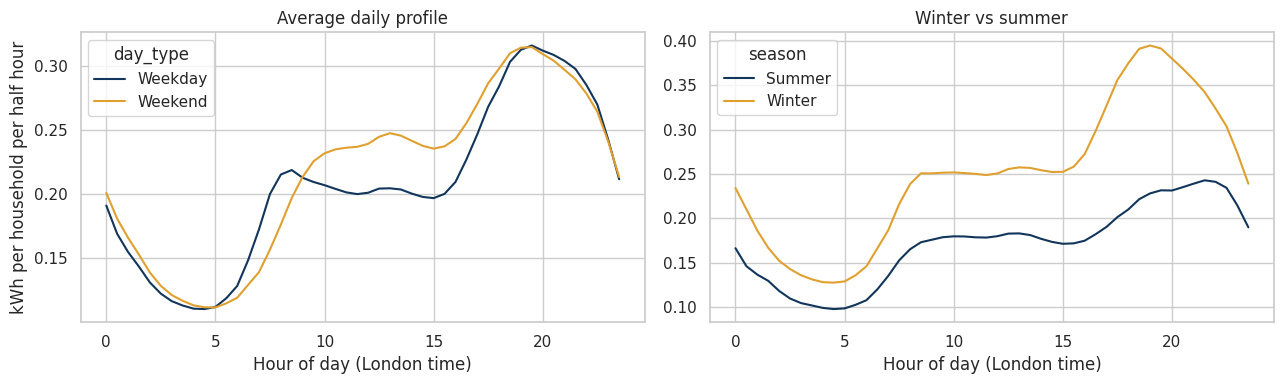

In [14]:
d = demand.copy()
local = to_local(d.index)
d["time_of_day"] = local.hour + local.minute / 60
d["day_type"] = np.where(local.dayofweek >= 5, "Weekend", "Weekday")
d["season"] = local.month.map({12: "Winter", 1: "Winter", 2: "Winter", 6: "Summer", 7: "Summer", 8: "Summer"})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=d, x="time_of_day", y="kwh_per_household", hue="day_type", errorbar=None, ax=axes[0],
             palette=["#12355B", "#E0A030"])
axes[0].set_title("Average daily profile")
axes[0].set_xlabel("Hour of day (London time)")
axes[0].set_ylabel("kWh per household per half hour")
sns.lineplot(data=d.dropna(subset=["season"]), x="time_of_day", y="kwh_per_household", hue="season",
             errorbar=None, ax=axes[1], palette=["#12355B", "#E0A030"])
axes[1].set_title("Winter vs summer")
axes[1].set_xlabel("Hour of day (London time)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

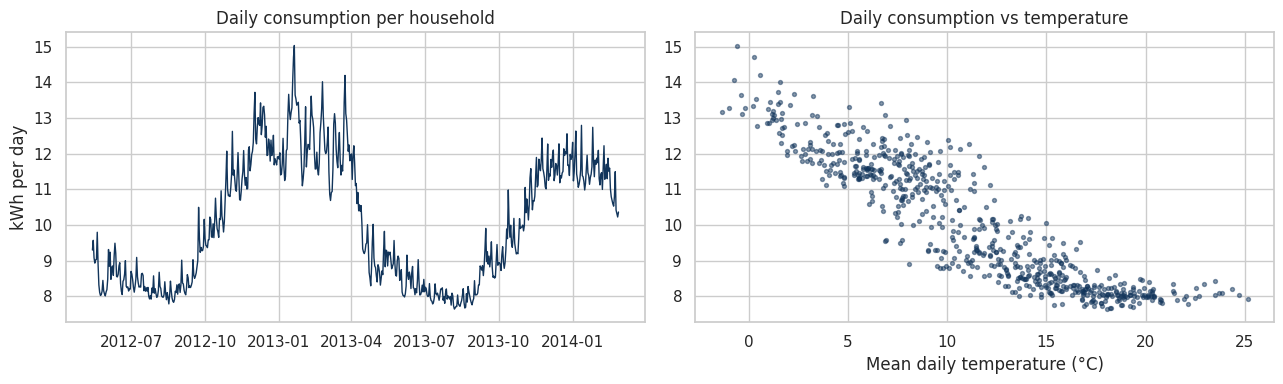

Correlation between daily temperature and consumption: -0.91


In [15]:
daily = demand.resample("D").agg({"kwh_per_household": "sum", "temperature": "mean", "holiday": "max"})
daily = daily.rename(columns={"kwh_per_household": "kwh_per_household_per_day"})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(daily.index, daily["kwh_per_household_per_day"], color="#12355B", lw=1)
axes[0].set_title("Daily consumption per household")
axes[0].set_ylabel("kWh per day")
axes[1].scatter(daily["temperature"], daily["kwh_per_household_per_day"], s=8, alpha=0.5, color="#12355B")
axes[1].set_title("Daily consumption vs temperature")
axes[1].set_xlabel("Mean daily temperature (°C)")
plt.tight_layout()
plt.show()

print(f"Correlation between daily temperature and consumption: {daily['temperature'].corr(daily['kwh_per_household_per_day']):.2f}")

**Observations** (times are London local time)

- Demand follows a clear daily rhythm: low overnight, a morning rise, and a strong **evening peak around 19:00 to 20:00** when people come home, cook, and switch on lights. Weekends start later in the morning and stay higher through the middle of the day.
- Winter evenings are much higher than summer evenings: more lighting, more time indoors, and some electric heating. In summer the evening peak is lower and later (around 21:00), following the later sunset.
- Daily consumption falls as temperature rises (correlation **-0.91**), from about 13 kWh per household on the coldest days to about 8 kWh on warm days.

## 6. Why the Target Matters: One Household vs Average Demand

A tempting first model predicts a single household's half-hourly reading from the time of day, day of week, and month. But two households at the same moment can use completely different amounts, and nothing in those features tells them apart. Averaging over thousands of households cancels out this individual randomness and leaves the shared pattern.

Here the same model and the same calendar features are fitted to both targets.

In [16]:
def calendar_features(index):
    local = to_local(index)
    return pd.DataFrame({"half_hour": local.hour * 2 + local.minute // 30,
                         "day_of_week": local.dayofweek, "month": local.month}, index=index)

sample = (clean.filter((F.col("ts") >= F.lit(str(START.date()))) & (F.col("ts") <= F.lit(str(END.date()))))
          .sample(fraction=0.005, seed=42).toPandas())
sample["ts"] = pd.to_datetime(sample["ts"])
sample = sample.sort_values("ts")
cut_individual = sample["ts"].quantile(0.8)

Xi = calendar_features(pd.DatetimeIndex(sample["ts"]))
yi = sample["energy"].values
tr_i = (sample["ts"] < cut_individual).values
m_ind = HistGradientBoostingRegressor(random_state=42).fit(Xi[tr_i], yi[tr_i])
r2_individual = r2_score(yi[~tr_i], m_ind.predict(Xi[~tr_i]))

Xa = calendar_features(demand.index)
ya = demand["kwh_per_household"].values
tr_a = demand.index < cut_individual
m_agg = HistGradientBoostingRegressor(random_state=42).fit(Xa[tr_a], ya[tr_a])
r2_average = r2_score(ya[~tr_a], m_agg.predict(Xa[~tr_a]))

pd.DataFrame({"Target": ["One household's reading", "Average per household"],
              "Test R² (calendar features only)": [r2_individual, r2_average]}).round(3)

,Target,Test R² (calendar features only)
0,One household's reading,0.053
1,Average per household,0.910


With identical features, the model explains only **5%** of the variation in a single household's readings (R² = 0.05), but **91%** of the variation in average demand (R² = 0.91). **Choosing the right target matters more than choosing the model.** The rest of the notebook forecasts average demand.

## 7. Day-Ahead Forecasting

**Setup:** each day at midnight, forecast all 48 half hours of the next day.

**Features**
- Calendar: half hour of the day, day of week, month, bank holiday flag
- Temperature for that half hour (the observed value stands in for a weather forecast)
- **Lags:** demand at the same half hour yesterday and one week ago, and yesterday's average demand. All of these are known at midnight.

**Evaluation:** a **time-based split**. Models train on the earlier period and are tested on the final four months, the way a forecast would actually be used.

**Metrics:** MAE (mean absolute error) is the size of the error averaged over every half hour in the test period, in **kWh per household per half hour**. It is an average: some individual half hours are forecast more accurately and some less. RMSE uses the same unit but penalises large errors more. MAPE is the average error as a percentage of actual demand.

In [17]:
feat = calendar_features(demand.index)
feat["holiday"] = demand["holiday"]
feat["temperature"] = demand["temperature"]
feat["lag_1_day"] = demand["kwh_per_household"].shift(48)
feat["lag_7_days"] = demand["kwh_per_household"].shift(336)
feat["yesterday_mean"] = demand["kwh_per_household"].resample("D").mean().shift(1).reindex(demand.index, method="ffill")
data = feat.assign(target=demand["kwh_per_household"]).dropna()

TEST_START = data.index.max().normalize() - pd.DateOffset(months=4)
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
FEATURES = [c for c in data.columns if c != "target"]
print(f"Train: {train.index.min().date()} to {train.index.max().date()} ({len(train):,} rows)")
print(f"Test:  {test.index.min().date()} to {test.index.max().date()} ({len(test):,} rows)")

Train: 2012-05-21 to 2013-10-26 (25,152 rows)
Test:  2013-10-27 to 2014-02-27 (5,952 rows)


In [18]:
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAPE (%)": 100 * np.mean(np.abs((y_true - y_pred) / y_true)),
            "R²": r2_score(y_true, y_pred)}

results = {
    "Baseline: same time yesterday": scores(test["target"], test["lag_1_day"]),
    "Baseline: same time last week": scores(test["target"], test["lag_7_days"]),
}

lin = LinearRegression().fit(pd.get_dummies(train[FEATURES], columns=["half_hour", "day_of_week", "month"]), train["target"])
X_test_lin = pd.get_dummies(test[FEATURES], columns=["half_hour", "day_of_week", "month"]).reindex(columns=lin.feature_names_in_, fill_value=0)
results["Linear Regression"] = scores(test["target"], lin.predict(X_test_lin))

gbm = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42).fit(train[FEATURES], train["target"])
pred_gbm = gbm.predict(test[FEATURES])
results["Gradient Boosting"] = scores(test["target"], pred_gbm)

results = pd.DataFrame(results).T
results.round({"MAE": 4, "RMSE": 4, "MAPE (%)": 1, "R²": 3})

,MAE,RMSE,MAPE (%),R²
Baseline: same time yesterday,0.0130,0.0209,5.5,0.930
Baseline: same time last week,0.0126,0.0187,5.4,0.944
Linear Regression,0.0101,0.0146,4.4,0.965
Gradient Boosting,0.0077,0.0111,3.3,0.980


In [19]:
improvement = 1 - results.loc["Gradient Boosting", "MAE"] / results.loc["Baseline: same time last week", "MAE"]
print(f"Gradient Boosting reduces the error of the 'same time last week' baseline by {improvement:.0%}")
print(f"Average demand in the test period: {test['target'].mean():.3f} kWh per household per half hour")
print(f"Gradient Boosting mean absolute error: {1000 * results.loc['Gradient Boosting', 'MAE']:.1f} Wh per household per half hour "
      f"(averaged over all {len(test):,} half hours in the test period)")

Gradient Boosting reduces the error of the 'same time last week' baseline by 39%
Average demand in the test period: 0.236 kWh per household per half hour
Gradient Boosting mean absolute error: 7.7 Wh per household per half hour (averaged over all 5,952 half hours in the test period)


### How much does observed temperature help?

The model uses the **observed** temperature (Dark Sky hourly weather observations) for the day being forecast. In real use only a weather forecast would be available at midnight, so this gives the model a slight advantage. To measure the largest possible size of that advantage, the model is retrained **without temperature at all**. A model fed a real weather forecast would land between the two results.

In [20]:
no_temp = [f for f in FEATURES if f != "temperature"]
gbm_no_temp = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42).fit(train[no_temp], train["target"])
comparison = pd.DataFrame({"With observed temperature": scores(test["target"], pred_gbm),
                           "Without temperature": scores(test["target"], gbm_no_temp.predict(test[no_temp]))}).T
print(f"Both models: same training period and the same {len(test):,} test half hours "
      f"({test.index.min().date()} to {test.index.max().date()}); only the temperature column differs")
comparison.round({"MAE": 4, "RMSE": 4, "MAPE (%)": 2, "R²": 3})

Both models: same training period and the same 5,952 test half hours (2013-10-27 to 2014-02-27); only the temperature column differs


,MAE,RMSE,MAPE (%),R²
With observed temperature,0.0077,0.0111,3.25,0.980
Without temperature,0.0086,0.0123,3.68,0.976


### Is the result stable across periods?

A single test period could be unusually easy or hard. As a robustness check, the model is evaluated with a **rolling origin**: for each of the last four calendar months, it is retrained on all data before that month and tested on that month only, exactly as it would be retrained in practice.

In [21]:
fold_rows = []
for start in pd.date_range(TEST_START.normalize() + pd.offsets.MonthBegin(1), data.index.max(), freq="MS"):
    end = start + pd.DateOffset(months=1)
    tr, te = data[data.index < start], data[(data.index >= start) & (data.index < end)]
    model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42).fit(tr[FEATURES], tr["target"])
    gbm_scores, base_scores = scores(te["target"], model.predict(te[FEATURES])), scores(te["target"], te["lag_7_days"])
    fold_rows.append({"Test month": start.strftime("%b %Y"),
                      "Training days": tr.index.normalize().nunique(),
                      "Baseline MAE (kWh)": base_scores["MAE"],
                      "Gradient Boosting MAE (kWh)": gbm_scores["MAE"],
                      "Baseline MAPE (%)": base_scores["MAPE (%)"],
                      "Gradient Boosting MAPE (%)": gbm_scores["MAPE (%)"],
                      "Error reduction vs baseline (%)": 100 * (1 - gbm_scores["MAE"] / base_scores["MAE"])})

folds = pd.DataFrame(fold_rows).set_index("Test month")
print(f"Gradient Boosting MAPE across months: {folds['Gradient Boosting MAPE (%)'].mean():.1f}% "
      f"± {folds['Gradient Boosting MAPE (%)'].std():.1f}")
folds.round({"Baseline MAE (kWh)": 4, "Gradient Boosting MAE (kWh)": 4, "Baseline MAPE (%)": 1, "Gradient Boosting MAPE (%)": 1, "Error reduction vs baseline (%)": 1})

Gradient Boosting MAPE across months: 3.1% ± 0.1


,Training days,Baseline MAE (kWh),Gradient Boosting MAE (kWh),Baseline MAPE (%),Gradient Boosting MAPE (%),Error reduction vs baseline (%)
Test month,,,,,,
Nov 2013,529,0.0134,0.0071,6.0,3.1,47.3
Dec 2013,559,0.0116,0.0083,4.7,3.3,28.5
Jan 2014,590,0.0121,0.0075,5.1,3.1,38.1
Feb 2014,621,0.0118,0.0071,5.2,3.0,40.2


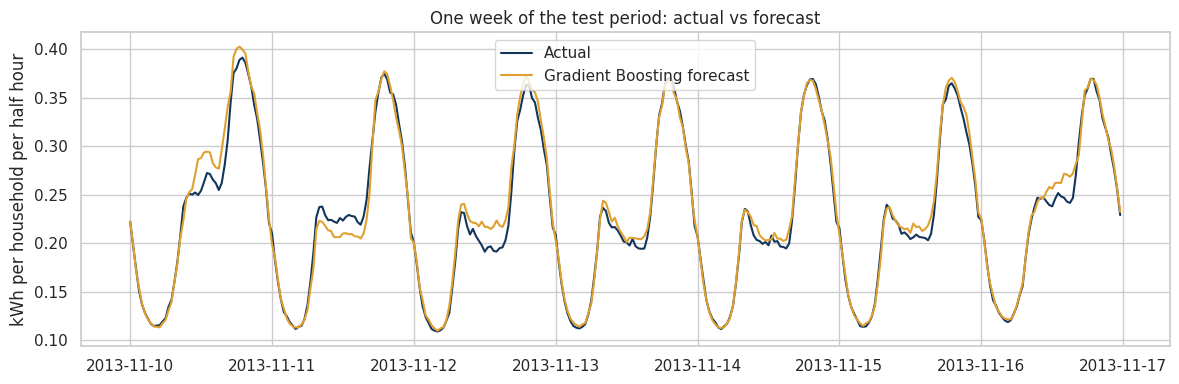

In [22]:
week = test.index.normalize().unique()[14:21]
w = test.index.normalize().isin(week)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index[w], test["target"][w], color="#12355B", label="Actual", lw=1.5)
ax.plot(test.index[w], pred_gbm[w], color="#E0A030", label="Gradient Boosting forecast", lw=1.5)
ax.set_title("One week of the test period: actual vs forecast")
ax.set_ylabel("kWh per household per half hour")
ax.legend()
plt.tight_layout()
plt.show()

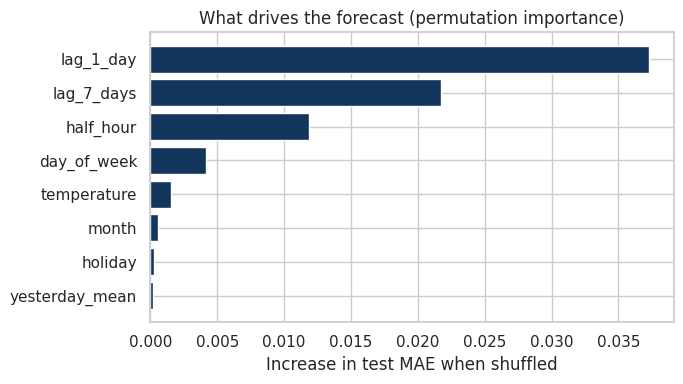

In [23]:
perm = permutation_importance(gbm, test[FEATURES], test["target"], scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=42)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color="#12355B")
ax.set_xlabel("Increase in test MAE when shuffled")
ax.set_title("What drives the forecast (permutation importance)")
plt.tight_layout()
plt.show()

In [24]:
# Which days are hardest to forecast?
day_errors = (pd.DataFrame({"abs_error": np.abs(test["target"] - pred_gbm)}, index=test.index)
              .resample("D").mean().sort_values("abs_error", ascending=False))
day_errors["holiday"] = day_errors.index.isin(holiday_dates)
day_errors.head(8)

,abs_error,holiday
ts,,
2013-12-25,0.019314,True
2014-01-01,0.018424,True
2014-01-02,0.017572,False
2013-12-26,0.016150,True
2014-01-26,0.015719,False
2013-12-21,0.014624,False
2014-02-13,0.014026,False
2013-12-15,0.013285,False


**Takeaways**

- Simple baselines are already strong (5.4% error for "same time last week"), because household demand repeats from day to day and week to week. Any model has to beat them to be worth using.
- **Gradient Boosting** reaches **3.3% MAPE** and **R² = 0.980**, cutting the error of the best baseline by **39%**. In absolute terms its mean absolute error is **7.7 Wh per household per half hour**, averaged over every half hour of the test period, against average demand of 236 Wh per household per half hour. Linear Regression sits in between (4.4%), so the non-linear model adds real value.
- **Observed temperature gives only a small advantage:** on exactly the same test set, removing temperature raises the error from 3.25% to 3.68%. A model fed a real weather forecast would land between the two, so the accuracy does not depend on knowing the weather in advance.
- **The result is stable:** retrained month by month, Gradient Boosting scores **3.1% ± 0.1** and beats the baseline in every one of the four months, by 28% to 47%.
- Yesterday's demand and last week's demand drive the forecast, followed by time of day. Temperature matters much less inside the model than in the exploratory analysis, because yesterday's demand already reflects the recent weather.
- The hardest days are **Christmas Day, Boxing Day, and 1 to 2 January**, when routines change. The holiday flag barely helps, because the training data contains only one Christmas period.

## 8. Did Time-of-Use Pricing Reduce Evening Peak Demand?

**Design: difference-in-differences.** Comparing ToU and standard households directly in 2013 could be misleading, because the two groups may have differed before the trial. Instead, for each household we measure the **share of its daily consumption used in the evening peak (16:00 to 20:00, London time)**, in 2012 and in 2013, and compare how much that share changed in each group.

Only households with at least 60 days of readings in April to December of **both** years are included, so meters installed late in 2012 or removed early in 2013 drop out. Household-years with zero total consumption (an empty home or a faulty meter) are also excluded, because a peak share cannot be calculated for them. The same months are used in both years so that seasonal effects cancel out.

**Statistical test:** each household contributes a single number, its change from 2012 to 2013, so the test compares independent households rather than millions of correlated half-hourly readings. With two periods, this is equivalent to clustering standard errors at the household level. A Welch t-test then compares the two groups without assuming equal variances.

In [25]:
info = spark.read.option("header", True).csv(HOUSEHOLDS_FILE).select("LCLid", "stdorToU")

peak_share = (clean
    .withColumn("local_ts", F.from_utc_timestamp("ts", "Europe/London"))
    .withColumn("year", F.year("local_ts")).withColumn("month", F.month("local_ts")).withColumn("hour", F.hour("local_ts"))
    .filter(F.col("year").isin(2012, 2013) & F.col("month").between(4, 12))
    .groupBy("LCLid", "year")
    .agg(F.sum(F.when(F.col("hour").between(16, 19), F.col("energy")).otherwise(0)).alias("peak_kwh"),
         F.sum("energy").alias("total_kwh"), F.count("*").alias("readings"))
    .filter(F.col("readings") > 48 * 60)
    .join(info, "LCLid")
    .toPandas())

# Some meters report zero for a whole year (vacant home or faulty meter); a share is undefined for them
zero_years = peak_share["total_kwh"] <= 0
print(f"Household-years with zero total consumption, excluded: {zero_years.sum()}")
peak_share = peak_share[~zero_years].copy()
peak_share["peak_share"] = peak_share["peak_kwh"] / peak_share["total_kwh"]

wide = peak_share.pivot_table(index=["LCLid", "stdorToU"], columns="year", values="peak_share").dropna().reset_index()
wide["change"] = wide[2013] - wide[2012]
print(f"Households in the tariff comparison: {len(wide):,} of {summary['households']:,}")
print(wide["stdorToU"].value_counts().to_string())

Household-years with zero total consumption, excluded: 4
Households in the tariff comparison: 5,327 of 5,561
stdorToU
Std    4238
ToU    1089


In [26]:
group_summary = wide.groupby("stdorToU")[[2012, 2013, "change"]].mean().mul(100)
group_summary.columns = ["Peak share 2012 (%)", "Peak share 2013 (%)", "Change (percentage points)"]

did = group_summary.loc["ToU", "Change (percentage points)"] - group_summary.loc["Std", "Change (percentage points)"]
tou_change = 100 * wide.loc[wide["stdorToU"] == "ToU", "change"]
std_change = 100 * wide.loc[wide["stdorToU"] == "Std", "change"]
t_stat, p_value = stats.ttest_ind(tou_change, std_change, equal_var=False)

# 95% confidence interval for the difference (Welch, unequal variances)
v_tou, v_std = tou_change.var() / len(tou_change), std_change.var() / len(std_change)
se = np.sqrt(v_tou + v_std)
dof = (v_tou + v_std) ** 2 / (v_tou ** 2 / (len(tou_change) - 1) + v_std ** 2 / (len(std_change) - 1))
ci_low, ci_high = did + np.array([-1, 1]) * stats.t.ppf(0.975, dof) * se

print(f"Difference-in-differences: {did:+.2f} percentage points")
print(f"95% confidence interval: {ci_low:+.2f} to {ci_high:+.2f} percentage points")
print(f"Welch t-test p-value: {p_value:.3f}")
group_summary.round(2)

Difference-in-differences: -0.14 percentage points
95% confidence interval: -0.30 to +0.02 percentage points
Welch t-test p-value: 0.088


,Peak share 2012 (%),Peak share 2013 (%),Change (percentage points)
stdorToU,,,
Std,22.13,21.41,-0.72
ToU,22.56,21.70,-0.86


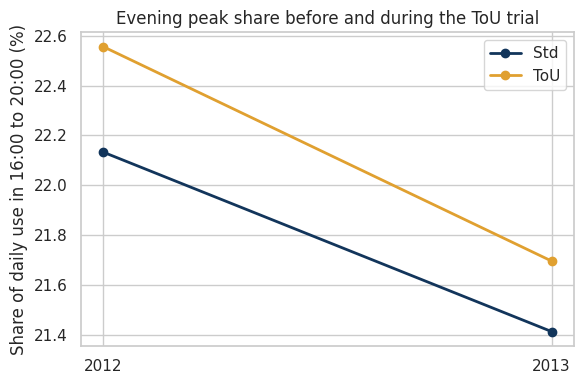

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
for group in ["Std", "ToU"]:
    ax.plot([2012, 2013], group_summary.loc[group, ["Peak share 2012 (%)", "Peak share 2013 (%)"]],
            marker="o", color=COLORS[group], label=group, lw=2)
ax.set_xticks([2012, 2013])
ax.set_ylabel("Share of daily use in 16:00 to 20:00 (%)")
ax.set_title("Evening peak share before and during the ToU trial")
ax.legend()
plt.tight_layout()
plt.show()

### Checking the parallel-trends assumption

Difference-in-differences relies on one key assumption: **without the tariff, both groups would have changed in the same way**. This cannot be proven, but it can be checked. If the gap between the groups was already drifting during 2012, before the trial began, a change in 2013 could simply be that drift continuing.

The same households are followed month by month from April 2012 to February 2014. The trial ran during 2013, so January and February 2014 also show what happened after it ended.

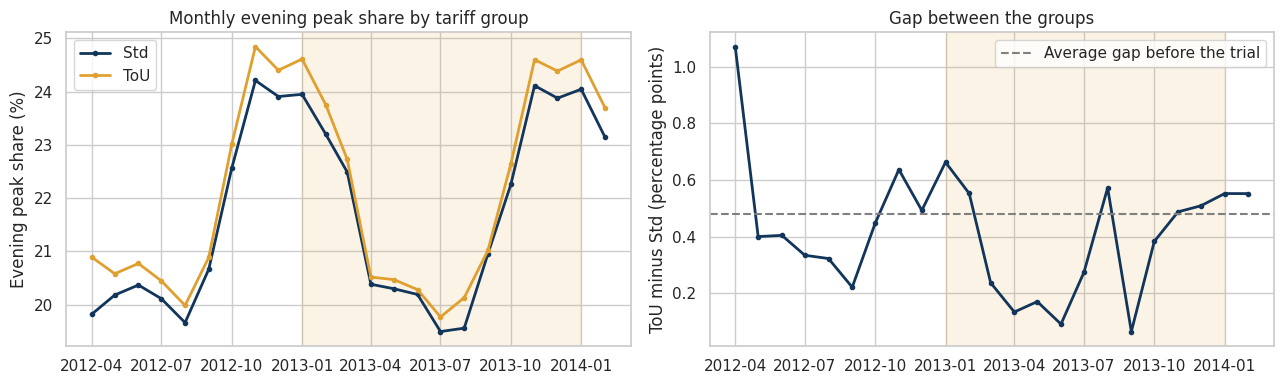

Trend in the gap before the trial: -0.027 percentage points per month


,Average gap (pp)
Before (Apr to Dec 2012),0.48
Trial (2013),0.35
After (Jan to Feb 2014),0.55


In [28]:
monthly = (clean
    .filter((F.col("ts") >= F.lit("2012-04-01")) & (F.col("ts") < F.lit("2014-03-01")))
    .withColumn("local_ts", F.from_utc_timestamp("ts", "Europe/London"))
    .withColumn("month", F.date_trunc("month", "local_ts")).withColumn("hour", F.hour("local_ts"))
    .groupBy("LCLid", "month")
    .agg(F.sum(F.when(F.col("hour").between(16, 19), F.col("energy")).otherwise(0)).alias("peak_kwh"),
         F.sum("energy").alias("total_kwh"), F.count("*").alias("readings"))
    .filter((F.col("readings") >= 48 * 20) & (F.col("total_kwh") > 0))
    .toPandas())

# Same households as the difference-in-differences above
monthly = monthly.merge(wide[["LCLid", "stdorToU"]], on="LCLid")
monthly["month"] = pd.to_datetime(monthly["month"])
monthly["peak_share"] = 100 * monthly["peak_kwh"] / monthly["total_kwh"]
trend = monthly.pivot_table(index="month", columns="stdorToU", values="peak_share", aggfunc="mean")
trend["gap"] = trend["ToU"] - trend["Std"]

period = np.select([trend.index < "2013-01-01", trend.index < "2014-01-01"],
                   ["Before (Apr to Dec 2012)", "Trial (2013)"], "After (Jan to Feb 2014)")
pre = trend[trend.index < "2013-01-01"]
pre_slope = np.polyfit(np.arange(len(pre)), pre["gap"], 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for group in ["Std", "ToU"]:
    axes[0].plot(trend.index, trend[group], marker="o", ms=3, color=COLORS[group], label=group, lw=2)
axes[0].set_ylabel("Evening peak share (%)")
axes[0].set_title("Monthly evening peak share by tariff group")
axes[0].legend()
axes[1].plot(trend.index, trend["gap"], marker="o", ms=3, color="#12355B", lw=2)
axes[1].axhline(pre["gap"].mean(), ls="--", c="grey", label="Average gap before the trial")
axes[1].set_ylabel("ToU minus Std (percentage points)")
axes[1].set_title("Gap between the groups")
axes[1].legend()
for ax in axes:
    ax.axvspan(pd.Timestamp("2013-01-01"), pd.Timestamp("2013-12-31"), color="#E0A030", alpha=0.12)
plt.tight_layout()
plt.show()

print(f"Trend in the gap before the trial: {pre_slope:+.3f} percentage points per month")
trend.groupby(period, sort=False)["gap"].mean().round(2).rename("Average gap (pp)").to_frame()

**Reading the result**

- Both groups used a smaller share of their electricity in the evening peak in 2013 than in 2012 (standard **-0.72** points, ToU **-0.86** points). The difference-in-differences is **-0.14 percentage points**, in the direction expected if ToU households shifted consumption away from the peak.
- **The effect is not statistically significant at the usual 5% level** (p = 0.088): the 95% confidence interval printed above includes zero, so the data is compatible with anything from a small reduction to no effect at all. Even the point estimate is small, about 0.6% of the ToU households' evening peak share.
- **Pre-trend check:** from May to December 2012 the gap between the groups moved between 0.22 and 0.66 points with no clear direction. The higher value in April 2012 comes from the smaller number of meters installed at that point and drives most of the slight negative trend printed above, so the parallel-trends assumption looks reasonable.
- **Timing:** the gap narrowed clearly in spring and early summer 2013, to around 0.1 points, then moved back towards its usual level by the end of the year and stayed there (0.55) after the trial ended. Any response to the tariff was therefore concentrated in part of the year rather than sustained throughout.

**Conclusion:** the data shows at most a **small** shift away from the evening peak, which cannot be clearly separated from normal variation between households. Time-of-use pricing, as run in this trial, did not produce a large change in when households used electricity.

**Caveats:** the dataset does not include the daily price signals sent to ToU households, so this measures the average effect over all days rather than the response to high-price days specifically, where a stronger response would be expected. The comparison is observational, not a controlled causal estimate.

## 9. Conclusion

- **PySpark** processed 167.8 million half-hourly readings from 5,561 households on a single machine. Text-encoded numbers, `Null` values, duplicates, a holidays file with day-first dates, and clock changes (all data turned out to be in GMT) were all checked and handled before any analysis.
- Demand is measured **per reporting household**, on complete days only, because the number of meters changed throughout the trial.
- **The choice of target matters more than the model:** with the same calendar features, a model explains 5% of a single household's readings but 91% of average demand.
- A **Gradient Boosting** day-ahead forecast reaches **3.3% MAPE** on the final four months, **39%** better than the best seasonal baseline, and stays at 3.1% ± 0.1 when retrained month by month. Removing temperature altogether, on the same test set, raises the error by less than half a percentage point.
- **Time-of-use pricing** shows at most a small shift away from the evening peak (-0.14 percentage points, p = 0.088, with a 95% confidence interval that includes zero), concentrated in spring and early summer 2013. The evidence does not support a large behavioural change.

### Limitations

- Observed temperature is used in place of a weather forecast. The test without temperature shows the advantage is small, but a real forecast would sit slightly below the reported accuracy.
- The training data contains only one Christmas period, so the model cannot learn festive-season behaviour well.
- The trial covers about two years of London households, so the patterns may not transfer to other regions or climates.
- The ToU analysis cannot separate responses to individual high-price days, because price signals are not in the dataset.